## 3. Critiques vs public (TMDB + Rotten)

*In `df_for_analysis.csv` the columns have no prefix: `rotten_critic_score_percentage` is `critic_score_percentage`, `tmdb_vote_average` is `vote_average`, etc.*

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SAVE_FIGS = True                                    
PLOTS_FOLDER = "critics_vs_audience_tmdb_rotten"    
MIN_GROUP = 20                                    

# go up from the notebook folder until we find the project's "data" folder
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)

def save_fig(title):
    # save the current figure in src/eda/plots/<notebook name>/<title>.png
    if SAVE_FIGS:
        path = os.path.join(ROOT, "src/eda/plots", PLOTS_FOLDER)
        os.makedirs(path, exist_ok=True)
        plt.savefig(os.path.join(path, f"{title}.png"), dpi=150, bbox_inches="tight")

def explode_genre(frame):
    # one row per (film, genre): a film with several genres counts once in each of them
    out = frame.dropna(subset=["genre"]).copy()
    out["genre"] = out["genre"].str.split(",")
    out = out.explode("genre")
    out["genre"] = out["genre"].str.strip()
    return out

def quartile_group(series):
    # 4 groups of equal size (rank first, because many films share the same count)
    return pd.qcut(series.rank(method="first"), 4, labels=["1 (fewest)", "2", "3", "4 (most)"])

df = pd.read_csv(os.path.join(ROOT, "data/merged/df_for_analysis.csv"))
df.shape

(81076, 27)

Le jeu de données contient 81 076 lignes et 27 colonnes ; on ne gardera que les films présents dans TMDB et Rotten.

In [2]:
df.columns

Index(['title', 'year', 'in_tmdb', 'in_numbers', 'in_rotten', 'n_sources',
       'release_date', 'popularity', 'vote_average', 'vote_count', 'rank',
       'domestic_box_office', 'international_box_office',
       'worldwide_box_office', 'domestic_share', 'genre', 'director',
       'original language', 'summary', 'critic_reviews_count',
       'critic_score_percentage', 'audience_score_percentage',
       'is_audience_rating_verified', 'audience_rating_count',
       'release_date_theaters_month', 'runtime_hour', 'runtime_minutes'],
      dtype='str')

### Sample: which films can we use?

In [3]:
# which source each film comes from
combo = df.groupby(["in_tmdb", "in_numbers", "in_rotten"]).size().rename("n_movies").reset_index()
display(combo)

,in_tmdb,in_numbers,in_rotten,n_movies
0,False,False,True,1635
1,False,True,False,193
2,False,True,True,4
3,True,False,False,77156
4,True,False,True,1485
5,True,True,False,416
6,True,True,True,187


Seuls 1 485 + 187 = 1 672 films sont à la fois dans TMDB et Rotten. C'est très peu par rapport aux 77 156 films présents uniquement dans TMDB.

In [4]:
# columns needed for this analysis
expected = ["title", "year", "genre", "vote_average", "vote_count",
            "critic_score_percentage", "critic_reviews_count",
            "audience_score_percentage", "audience_rating_count",
            "is_audience_rating_verified"]
print("Missing columns:", [c for c in expected if c not in df.columns])   # must be []

# films present in both TMDB and Rotten Tomatoes
both = df[(df["in_tmdb"] == True) & (df["in_rotten"] == True)].copy()

# make sure the numeric columns are numeric
for col in ["year", "vote_average", "vote_count",
            "critic_score_percentage", "critic_reviews_count",
            "audience_score_percentage", "audience_rating_count"]:
    both[col] = pd.to_numeric(both[col], errors="coerce")

# % of missing values inside this sample
(both[expected].isna().mean() * 100).round(1).sort_values(ascending=False)

Missing columns: []


title                          0.0
year                           0.0
genre                          0.0
vote_average                   0.0
vote_count                     0.0
critic_score_percentage        0.0
critic_reviews_count           0.0
audience_score_percentage      0.0
audience_rating_count          0.0
is_audience_rating_verified    0.0
dtype: float64

Aucune valeur manquante dans les colonnes utiles pour les films TMDB + Rotten : on peut analyser sans retirer de lignes à ce stade.

In [5]:
# sample for critics vs audience (gap, genres, number of reviews, verified): films with both Rotten Tomatoes scores
rt = both.dropna(subset=["critic_score_percentage", "audience_score_percentage"]).copy()
rt["gap"] = rt["audience_score_percentage"] - rt["critic_score_percentage"]   # > 0 : the audience rates the film higher than the critics

# sample for Rotten vs TMDB: films with at least one TMDB vote (vote_average = 0 with 0 votes means "nobody voted")
rt_tmdb = rt[rt["vote_count"] >= 1].copy()
rt_tmdb["tmdb_score_100"] = rt_tmdb["vote_average"] * 10
rt_tmdb["tmdb_diff"] = rt_tmdb["audience_score_percentage"] - rt_tmdb["tmdb_score_100"]   # > 0 : RT audience higher than TMDB x 10

print("TMDB + Rotten films                       :", len(both))
print("... with both Rotten scores (critics vs audience) :", len(rt))
print("... and at least one TMDB vote (Rotten vs TMDB):", len(rt_tmdb))
print("Years covered:", sorted(int(y) for y in rt["year"].dropna().unique()))

TMDB + Rotten films                       : 1672
... with both Rotten scores (critics vs audience) : 1672
... and at least one TMDB vote (Rotten vs TMDB): 1657
Years covered: [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


Les échantillons sont fixés : 1 672 films pour l'analyse critiques vs public, et 1 657 pour la comparaison Rotten vs TMDB (15 films sans vote TMDB). Les années vont de 2019 à 2026.

###
1. **Les critiques et le public sont-ils d'accord ?** Étudiez la corrélation entre `rotten_critic_score_percentage` et `rotten_audience_score_percentage`, et l'écart (audience − critique) en fonction du genre.

In [6]:
x, y = "critic_score_percentage", "audience_score_percentage"

print("Number of films:", len(rt))
print("Pearson :", round(rt[x].corr(rt[y]), 3))
print("Spearman:", round(rt[x].corr(rt[y], method="spearman"), 3))   # spearman because of the outliers

Number of films: 1672
Pearson : 0.454
Spearman: 0.435


Corrélation modérée (Spearman 0,44) sur 1 672 films : critiques et public vont dans le même sens, mais l'accord est loin d'être total.

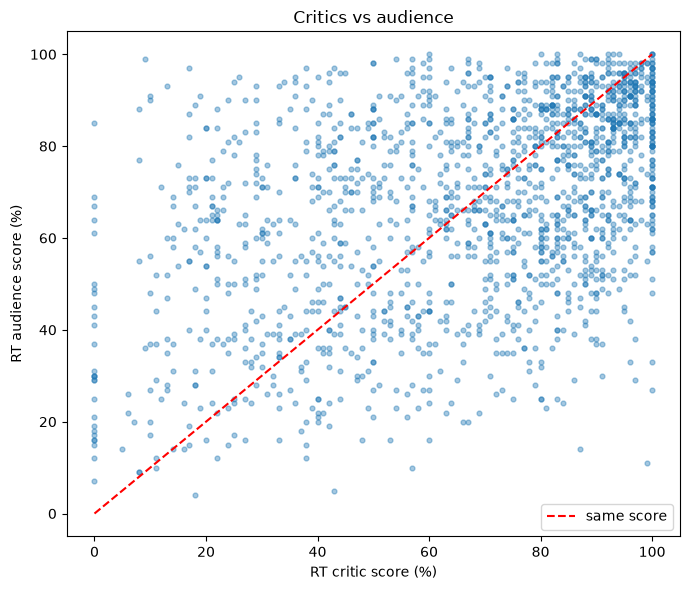

In [7]:
plt.figure(figsize=(7, 6))
plt.scatter(rt["critic_score_percentage"], rt["audience_score_percentage"], alpha=0.4, s=12)
plt.plot([0, 100], [0, 100], "r--", label="same score")
plt.xlabel("RT critic score (%)")
plt.ylabel("RT audience score (%)")
plt.title("Critics vs audience")
plt.legend()
plt.tight_layout()
save_fig("Critics vs audience scatter")
plt.show()

Le nuage est très dispersé autour de la diagonale « même score », ce qui correspond à une corrélation de 0,44 seulement : beaucoup de films ont des notes différentes selon le camp.

mean gap (audience - critics): 0.2
median gap: -2.0
audience rates higher than the critics: 45.2 % of the films
films with |gap| > 20 points: 672 (40.2%)


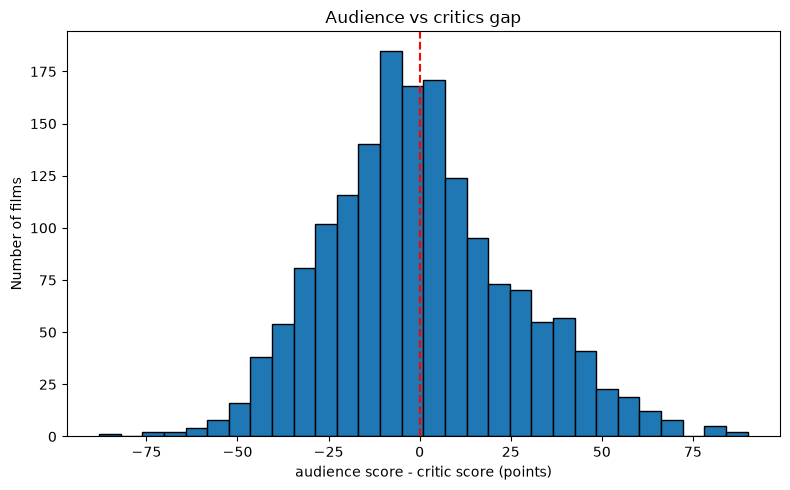

In [8]:
# gap = audience - critics
gap = rt["gap"]
print("mean gap (audience - critics):", round(gap.mean(), 1))
print("median gap:", round(gap.median(), 1))
print("audience rates higher than the critics:", round((gap > 0).mean() * 100, 1), "% of the films")
print("films with |gap| > 20 points:", (gap.abs() > 20).sum(), f"({(gap.abs() > 20).mean() * 100:.1f}%)")

plt.figure(figsize=(8, 5))
plt.hist(gap, bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("audience score - critic score (points)")
plt.ylabel("Number of films")
plt.title("Audience vs critics gap")
plt.tight_layout()
save_fig("Audience vs critics gap")
plt.show()

L'écart moyen est quasi nul (+0,2) et le médian légèrement négatif (−2), donc il n'y a pas de camp systématiquement plus généreux. Pourtant 40 % des films ont plus de 20 points d'écart : les désaccords individuels sont grands.

a positive gap means that the audience likes the film more than the critics do

In [9]:
# gap by genre
genre_gap = (
    explode_genre(rt)
    .groupby("genre")
    .agg(
        n_films=("title", "count"),
        mean_gap=("gap", "mean"),
        median_gap=("gap", "median")
    )
    .query("n_films >= @MIN_GROUP")
    .sort_values("median_gap")
)

# correlation critics / audience inside each genre
genre_data = explode_genre(rt)
genre_gap["spearman_critic_audience"] = [
    genre_data.loc[genre_data["genre"] == g, "critic_score_percentage"]
    .corr(genre_data.loc[genre_data["genre"] == g, "audience_score_percentage"], method="spearman")
    for g in genre_gap.index
]

display(genre_gap.round(2))

,n_films,mean_gap,median_gap,spearman_critic_audience
genre,,,,
Horror,274,-9.15,-11.5,0.33
LGBTQ+,38,-6.39,-7.5,0.31
Documentary,225,-8.76,-7.0,0.25
Holiday,49,-2.00,-5.0,0.45
Musical,22,-1.32,-2.5,0.18
Sci-Fi,106,1.14,-2.0,0.30
Drama,675,0.78,-1.0,0.35
Comedy,510,1.85,-1.0,0.43
Mystery & Thriller,532,0.15,-1.0,0.40


Le public est plus généreux en Action (+10 points d'écart médian) et Aventure (+7), plus sévère en Horreur (−11,5) et Documentaire (−7). L'accord est le plus fort en Crime (0,58) et le plus faible pour le Musical (0,18, n = 22) : à prendre avec prudence sur les petits groupes.

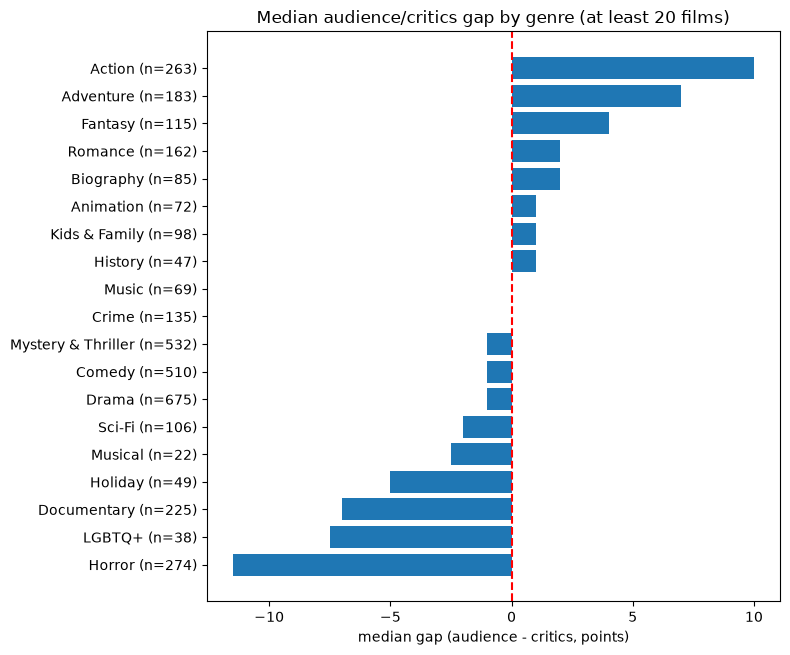

In [10]:
if len(genre_gap) > 0:
    labels = [f"{g} (n={n})" for g, n in zip(genre_gap.index, genre_gap["n_films"])]
    plt.figure(figsize=(8, max(4, len(genre_gap) * 0.35)))
    plt.barh(labels, genre_gap["median_gap"])
    plt.axvline(0, color="red", linestyle="--")
    plt.xlabel("median gap (audience - critics, points)")
    plt.title(f"Median audience/critics gap by genre (at least {MIN_GROUP} films)")
    plt.tight_layout()
    save_fig("Median gap by genre")
    plt.show()
else:
    print("No genre with enough films: lower MIN_GROUP")

Le graphique reprend le tableau précédent : la plupart des genres sont proches de 0, seuls quelques-uns (Action, Aventure, Horreur) s'en écartent nettement.

###
2. **Quels genres ont les plus grands écarts critique/public ?** Quels films sont « aimés du public mais rejetés par la critique », et inversement ?

In [11]:
print("Genres where the audience rates much HIGHER than the critics:")
display(genre_gap.sort_values("median_gap", ascending=False).head(5).round(1))

print("Genres where the audience rates much LOWER than the critics:")
display(genre_gap.sort_values("median_gap").head(5).round(1))

Genres where the audience rates much HIGHER than the critics:


,n_films,mean_gap,median_gap,spearman_critic_audience
genre,,,,
Action,263,11.3,10.0,0.5
Adventure,183,10.2,7.0,0.5
Fantasy,115,5.3,4.0,0.3
Romance,162,5.2,2.0,0.4
Biography,85,5.1,2.0,0.3


Genres where the audience rates much LOWER than the critics:


,n_films,mean_gap,median_gap,spearman_critic_audience
genre,,,,
Horror,274,-9.1,-11.5,0.3
LGBTQ+,38,-6.4,-7.5,0.3
Documentary,225,-8.8,-7.0,0.2
Holiday,49,-2.0,-5.0,0.5
Musical,22,-1.3,-2.5,0.2


Les cinq genres où le public est le plus haut sont Action, Aventure, Fantasy, Romance et Biographie ; les cinq où il est le plus bas sont Horreur, LGBTQ+, Documentaire, Holiday et Musical.

In [12]:
# definition of "loved" and "rejected" (scores in %), change the thresholds if a list is empty
PUBLIC_HIGH, CRITIC_LOW = 70, 40      # loved by the public, rejected by the critics
CRITIC_HIGH, PUBLIC_LOW = 70, 40      # loved by the critics, rejected by the public

cols = ["title", "year", "genre", "critic_score_percentage", "audience_score_percentage", "gap"]

loved_by_public = rt[(rt["audience_score_percentage"] >= PUBLIC_HIGH) & (rt["critic_score_percentage"] <= CRITIC_LOW)]
loved_by_critics = rt[(rt["critic_score_percentage"] >= CRITIC_HIGH) & (rt["audience_score_percentage"] <= PUBLIC_LOW)]

print(f"Loved by the public (>= {PUBLIC_HIGH}%) but rejected by the critics (<= {CRITIC_LOW}%):",
      len(loved_by_public), f"films ({len(loved_by_public) / len(rt) * 100:.1f}% of the sample)")
display(loved_by_public.sort_values("gap", ascending=False)[cols].head(15))

Loved by the public (>= 70%) but rejected by the critics (<= 40%): 84 films (5.0% of the sample)


,title,year,genre,critic_score_percentage,audience_score_percentage,gap
76349,Melania,2026.0,"Documentary, Biography",9.0,99.0,90.0
9959,The Tashkent Files,2019.0,"Drama, Mystery & Thriller",0.0,85.0,85.0
73039,Clika,2026.0,"Drama, Music",10.0,91.0,81.0
11527,After We Collided,2020.0,"Romance, Drama",13.0,93.0,80.0
73017,Citizen Vigilante,2026.0,"Action, Mystery & Thriller, Crime",10.0,90.0,80.0
38917,Stoker Hills,2022.0,"Horror, Mystery & Thriller, Action",17.0,97.0,80.0
31858,American Siege,2022.0,"Action, Mystery & Thriller",8.0,88.0,80.0
70076,The Ruse,2025.0,Mystery & Thriller,19.0,91.0,72.0
52837,Camp Pleasant Lake,2024.0,"Horror, Mystery & Thriller",18.0,89.0,71.0
11208,2 Hearts,2020.0,"Romance, Drama",17.0,87.0,70.0


84 films (5,0 %) sont aimés du public mais rejetés par la critique. Les écarts vont jusqu'à 90 points (Melania). On y trouve beaucoup de thrillers, d'action et de romances.

In [13]:
print(f"Loved by the critics (>= {CRITIC_HIGH}%) but rejected by the public (<= {PUBLIC_LOW}%):",
      len(loved_by_critics), f"films ({len(loved_by_critics) / len(rt) * 100:.1f}% of the sample)")
display(loved_by_critics.sort_values("gap")[cols].head(15))

Loved by the critics (>= 70%) but rejected by the public (<= 40%): 45 films (2.7% of the sample)


,title,year,genre,critic_score_percentage,audience_score_percentage,gap
5593,Knock Down the House,2019.0,Documentary,99.0,11.0,-88.0
1957,Artik,2019.0,Horror,100.0,27.0,-73.0
13176,Cuties,2020.0,"Comedy, Drama",87.0,14.0,-73.0
60360,Tiger Stripes,2024.0,Horror,97.0,29.0,-68.0
45607,King of Clones,2023.0,Documentary,100.0,33.0,-67.0
66057,Lesbian Space Princess,2025.0,"Sci-Fi, Fantasy, Comedy, LGBTQ+, Animation",96.0,33.0,-63.0
40852,We're All Going to the World's Fair,2022.0,"Horror, Drama",91.0,30.0,-61.0
18414,She Dies Tomorrow,2020.0,"Mystery & Thriller, Drama",84.0,24.0,-60.0
67773,Predators,2025.0,Documentary,97.0,38.0,-59.0
4456,Girl on the Third Floor,2019.0,"Horror, Mystery & Thriller",81.0,23.0,-58.0


45 films (2,7 %) sont dans le cas inverse, soit presque deux fois moins. Ce sont surtout des films d'horreur et des documentaires bien notés par la critique (Knock Down the House, Cuties, Tiger Stripes).

In [14]:
# what do these films have in common? Main genres of each group, compared with the whole sample
def top_genres(frame, n=6):
    return explode_genre(frame)["genre"].value_counts(normalize=True).mul(100).round(1).head(n)

profile = pd.DataFrame({
    "loved by the public (%)": top_genres(loved_by_public, 12),
    "loved by the critics (%)": top_genres(loved_by_critics, 12),
    "whole sample (%)": top_genres(rt, 12),
}).dropna(how="all")
display(profile)

,loved by the public (%),loved by the critics (%),whole sample (%)
genre,,,
Action,10.4,2.1,7.0
Adventure,5.5,1.1,4.9
Biography,2.2,NaN,NaN
Comedy,12.0,10.6,13.7
Crime,4.4,2.1,3.6
Documentary,NaN,7.4,6.0
Drama,20.2,18.1,18.1
Fantasy,2.7,5.3,3.1
History,1.6,NaN,NaN


Les films aimés du public sont plus souvent de l'Action et du Mystery & Thriller que dans l'échantillon entier ; ceux aimés des critiques sont surtout de l'Horreur (19 % contre 7 %) et du Documentaire.

In [15]:
# the same films by year
by_year = pd.DataFrame({
    "loved by the public": loved_by_public["year"].value_counts(),
    "loved by the critics": loved_by_critics["year"].value_counts(),
    "all films of the sample": rt["year"].value_counts(),
}).sort_index().fillna(0).astype(int)
display(by_year)

,loved by the public,loved by the critics,all films of the sample
year,,,
2019.0,23,8,373
2020.0,10,8,179
2021.0,0,1,21
2022.0,17,14,317
2023.0,13,6,312
2024.0,2,2,47
2025.0,8,6,270
2026.0,11,0,153


Pas de schéma net par année : les films en désaccord se répartissent à peu près comme l'échantillon. 2021 et 2024 ont trop peu de films pour conclure.

###
3. **Le score public de Rotten est-il cohérent avec `tmdb_vote_average × 10` ?** Qu'est-ce qui explique les différences ?

In [16]:
print("Number of films:", len(rt_tmdb))
print("Pearson :", round(rt_tmdb["audience_score_percentage"].corr(rt_tmdb["tmdb_score_100"]), 3))
print("Spearman:", round(rt_tmdb["audience_score_percentage"].corr(rt_tmdb["tmdb_score_100"], method="spearman"), 3))

d = rt_tmdb["tmdb_diff"]
print("mean difference (RT audience - TMDB x10):", round(d.mean(), 1))
print("median difference:", round(d.median(), 1))
print("mean absolute difference:", round(d.abs().mean(), 1))
print("within +/- 10 points:", round((d.abs() <= 10).mean() * 100, 1), "% of the films")
print("within +/- 20 points:", round((d.abs() <= 20).mean() * 100, 1), "% of the films")

# if the two scores were the same measure, we would get audience = 1 x (TMDB x 10) + 0
slope, intercept = np.polyfit(rt_tmdb["tmdb_score_100"], rt_tmdb["audience_score_percentage"], 1)
print(f"fitted line: audience = {slope:.2f} x (TMDB x 10) + {intercept:.1f}")

Number of films: 1657
Pearson : 0.558
Spearman: 0.615
mean difference (RT audience - TMDB x10): 4.4
median difference: 7.0
mean absolute difference: 15.4
within +/- 10 points: 35.7 % of the films
within +/- 20 points: 70.7 % of the films
fitted line: audience = 1.25 x (TMDB x 10) + -11.7


Les deux scores classent assez bien les films de la même façon (Spearman 0,62), mieux que critiques et public. Mais ils ne sont pas équivalents : écart absolu moyen de 15 points et seulement 36 % des films à ±10 points. La pente de 1,25 montre que Rotten est plus étalé que TMDB × 10.

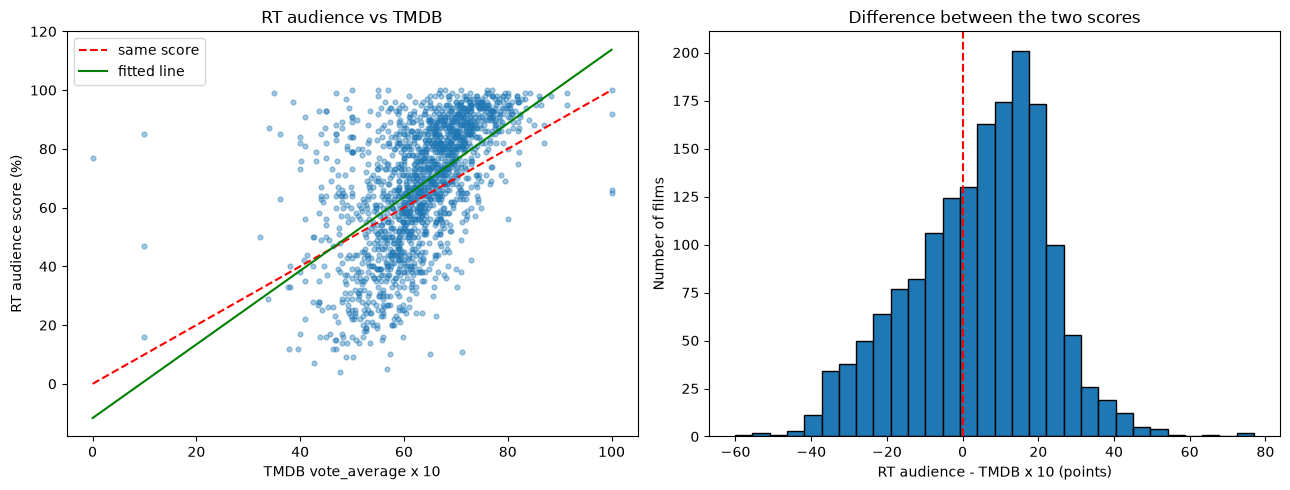

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(rt_tmdb["tmdb_score_100"], rt_tmdb["audience_score_percentage"], alpha=0.4, s=12)
axes[0].plot([0, 100], [0, 100], "r--", label="same score")
xs = np.array([rt_tmdb["tmdb_score_100"].min(), rt_tmdb["tmdb_score_100"].max()])
axes[0].plot(xs, slope * xs + intercept, "g-", label="fitted line")
axes[0].set(xlabel="TMDB vote_average x 10", ylabel="RT audience score (%)", title="RT audience vs TMDB")
axes[0].legend()

axes[1].hist(rt_tmdb["tmdb_diff"], bins=30, edgecolor="black")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set(xlabel="RT audience - TMDB x 10 (points)", ylabel="Number of films", title="Difference between the two scores")

plt.tight_layout()
save_fig("RT audience vs TMDB")
plt.show()

À gauche, le nuage suit la tendance mais s'écarte de la diagonale « même score » ; à droite, l'histogramme des écarts est décalé vers les valeurs positives (médiane +7), ce qui veut dire que Rotten est plus souvent au-dessus de TMDB × 10.

Hypothesis to check: Rotten Tomatoes gives a **percentage** (to our knowledge, the share of positive ratings) whereas TMDB gives an **average** on 10. These are two different measures, so we do not expect audience = TMDB x 10 exactly. The slope of the fitted line above tells how far from 1 to 1 the relation is.

In [18]:
# What explains the differences? 1) number of TMDB votes: an average on few votes is noisy
rt_tmdb["tmdb_votes_group"] = pd.cut(
    rt_tmdb["vote_count"], bins=[0, 9, 49, 199, 999, np.inf],
    labels=["1-9", "10-49", "50-199", "200-999", "1000+"]
)

by_votes = (
    rt_tmdb.groupby("tmdb_votes_group", observed=True)
           .agg(
               n_films=("title", "count"),
               median_diff=("tmdb_diff", "median"),
               median_abs_diff=("tmdb_diff", lambda s: s.abs().median()),
               std_diff=("tmdb_diff", "std")
           )
)
display(by_votes.round(1))

,n_films,median_diff,median_abs_diff,std_diff
tmdb_votes_group,,,,
1-9,92,17.5,19.6,22.9
10-49,354,12.0,15.9,17.8
50-199,517,3.6,14.0,18.1
200-999,434,1.5,13.2,17.6
1000+,260,10.9,13.3,12.3


Plus un film a de votes TMDB, plus les deux scores se rapprochent : l'écart absolu médian baisse de 19,6 à 13,3 et la dispersion de 22,9 à 12,3. Un écart d'environ 13 points subsiste même à plus de 1 000 votes, donc les deux mesures restent différentes.

In [19]:
# 2) release year
by_year_diff = (
    rt_tmdb.dropna(subset=["year"])
           .groupby("year")
           .agg(n_films=("title", "count"), median_diff=("tmdb_diff", "median"),
                median_abs_diff=("tmdb_diff", lambda s: s.abs().median()))
           .sort_index()
)
display(by_year_diff.round(1))

,n_films,median_diff,median_abs_diff
year,,,
2019.0,373,8.1,14.0
2020.0,177,3.0,15.0
2021.0,18,9.7,14.5
2022.0,315,5.7,14.9
2023.0,311,7.5,13.7
2024.0,46,10.3,12.3
2025.0,269,5.7,15.0
2026.0,148,8.6,12.5


L'écart médian varie de +3 à +10 selon l'année, sans tendance claire ; 2021 et 2024 ont peu de films (18 et 46). L'année explique donc peu de chose.

In [20]:
# 3) genre
genre_diff = (
    explode_genre(rt_tmdb)
    .groupby("genre")
    .agg(n_films=("title", "count"), median_diff=("tmdb_diff", "median"),
         median_abs_diff=("tmdb_diff", lambda s: s.abs().median()))
    .query("n_films >= @MIN_GROUP")
    .sort_values("median_diff")
)
display(genre_diff.round(1))

,n_films,median_diff,median_abs_diff
genre,,,
Horror,272,-3.8,12.9
Mystery & Thriller,528,0.8,14.2
Romance,161,3.3,12.3
Crime,135,3.6,14.6
Holiday,49,3.9,13.8
Sci-Fi,105,4.0,14.0
Action,262,6.8,15.5
Fantasy,114,7.2,14.0
Comedy,509,8.0,13.6


Le genre explique davantage : l'écart médian va de −3,8 (Horreur) à +16,6 (Biographie), avec Documentaire et Musique aussi très positifs. L'écart absolu reste proche partout (12 à 17).

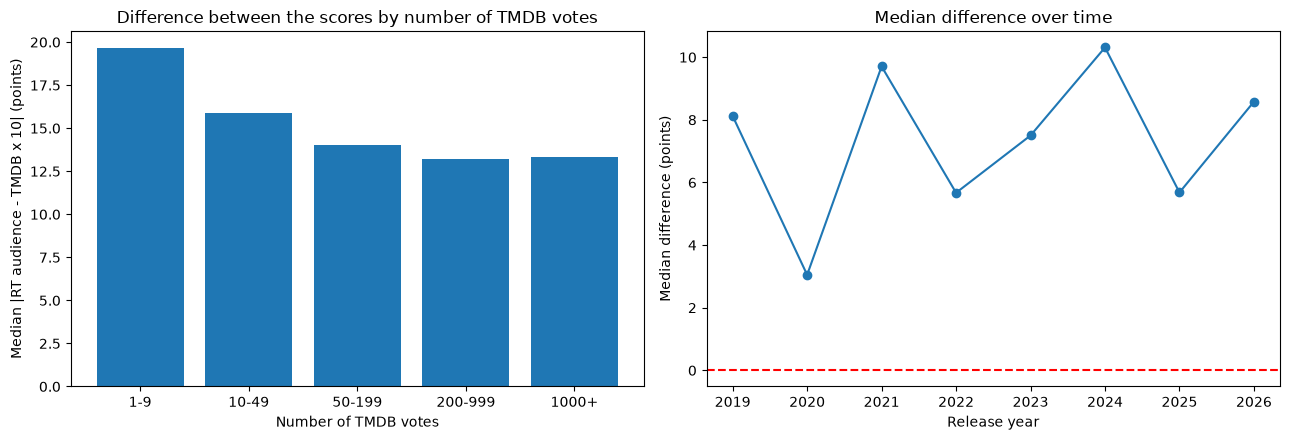

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(by_votes.index.astype(str), by_votes["median_abs_diff"])
axes[0].set(xlabel="Number of TMDB votes", ylabel="Median |RT audience - TMDB x 10| (points)",
            title="Difference between the scores by number of TMDB votes")

axes[1].plot(by_year_diff.index, by_year_diff["median_diff"], marker="o")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Release year", ylabel="Median difference (points)", title="Median difference over time")

plt.tight_layout()
save_fig("What explains the RT vs TMDB differences")
plt.show()

Le graphique de gauche confirme que l'écart diminue quand les votes TMDB augmentent ; celui de droite montre que l'écart médian reste positif toutes les années.

In [22]:
# the films with the largest differences, to look for an explanation
cols = ["title", "year", "genre", "audience_score_percentage", "tmdb_score_100", "vote_count", "tmdb_diff"]

print("RT audience much HIGHER than TMDB x 10:")
display(rt_tmdb.nlargest(10, "tmdb_diff")[cols])

print("RT audience much LOWER than TMDB x 10:")
display(rt_tmdb.nsmallest(10, "tmdb_diff")[cols])

RT audience much HIGHER than TMDB x 10:


,title,year,genre,audience_score_percentage,tmdb_score_100,vote_count,tmdb_diff
2729,Candy,2019.0,"Drama, Romance",77.0,0.00,1.0,77.00
33376,Dash,2022.0,Mystery & Thriller,85.0,10.00,2.0,75.00
76349,Melania,2026.0,"Documentary, Biography",99.0,35.00,184.0,64.00
12546,Buoyancy,2020.0,Drama,96.0,38.57,7.0,57.43
78395,She Dances,2026.0,"Comedy, Drama",87.0,34.00,5.0,53.00
49470,The Cow Who Sang a Song into the Future,2023.0,Drama,99.0,47.00,16.0,52.00
53399,Dagr,2024.0,"Horror, Mystery & Thriller, Comedy",91.0,40.93,27.0,50.07
35108,"I, Challenger",2022.0,Comedy,100.0,50.00,4.0,50.00
40249,Those Who Walk Away,2022.0,"Horror, Mystery & Thriller",93.0,43.70,23.0,49.30
57909,Project Dorothy,2024.0,"Sci-Fi, Mystery & Thriller",85.0,36.07,14.0,48.93


RT audience much LOWER than TMDB x 10:


,title,year,genre,audience_score_percentage,tmdb_score_100,vote_count,tmdb_diff
5593,Knock Down the House,2019.0,Documentary,11.0,71.11,185.0,-60.11
8089,Ruby,2019.0,Horror,10.0,65.00,2.0,-55.00
34550,Girl at the Window,2022.0,"Mystery & Thriller, Horror",5.0,56.73,107.0,-51.73
32642,Bring It On: Cheer Or Die,2022.0,"Mystery & Thriller, Horror, Comedy",10.0,57.26,164.0,-47.26
39456,The Desperate Hour,2022.0,"Mystery & Thriller, Drama",16.0,59.72,488.0,-43.72
39945,The Requin,2022.0,"Mystery & Thriller, Adventure",4.0,47.62,385.0,-43.62
13857,Endless,2020.0,"Romance, Drama",23.0,66.17,223.0,-43.17
37782,Pursuit,2022.0,"Action, Mystery & Thriller, Drama",9.0,50.14,73.0,-41.14
61793,Alarum,2025.0,"Action, Mystery & Thriller, Crime",15.0,55.86,417.0,-40.86
37301,Operation Seawolf,2022.0,"War, Drama, Action",16.0,56.00,119.0,-40.00


Les plus grands écarts positifs viennent souvent de films avec très peu de votes TMDB (1 à 7 votes), donc une moyenne peu fiable. Les plus grands écarts négatifs sont surtout des thrillers et films d'action de 2022 notés bas par le public Rotten.

###
4. **L'accord critique/public dépend-il du nombre d'avis** (`rotten_critic_reviews_count`, `rotten_audience_rating_count`) ? Un score reposant sur peu d'avis est-il plus extrême ?

In [23]:
rt["abs_gap"] = rt["gap"].abs()     # 0 = perfect agreement, large = disagreement

# do critics and audience disagree less when there are more reviews?
for col in ["critic_reviews_count", "audience_rating_count"]:
    data = rt[[col, "abs_gap"]].dropna()
    rho = data[col].corr(data["abs_gap"], method="spearman")
    print(f"{col} vs |gap|: n = {len(data)}, Spearman = {rho:.3f}")

critic_reviews_count vs |gap|: n = 1672, Spearman = -0.133
audience_rating_count vs |gap|: n = 1672, Spearman = -0.037


Les films avec plus d'avis critiques ont un peu moins d'écart (Spearman −0,13) ; pour les notes du public, le lien est presque nul (−0,04).

In [24]:
def agreement_by_group(frame, count_col):
    data = frame.dropna(subset=[count_col]).copy()
    data["group"] = quartile_group(data[count_col])
    rows = []
    for name, g in data.groupby("group", observed=True):
        rows.append({
            "group": name,
            "min_count": g[count_col].min(),
            "max_count": g[count_col].max(),
            "n_films": len(g),
            "median_abs_gap": g["abs_gap"].median(),
            "spearman_critic_vs_audience": g["critic_score_percentage"].corr(g["audience_score_percentage"], method="spearman"),
        })
    return pd.DataFrame(rows).set_index("group")

print("Agreement by number of CRITIC reviews:")
display(agreement_by_group(rt, "critic_reviews_count").round(2))

print("Agreement by number of AUDIENCE ratings:")
display(agreement_by_group(rt, "audience_rating_count").round(2))

Agreement by number of CRITIC reviews:


,min_count,max_count,n_films,median_abs_gap,spearman_critic_vs_audience
group,,,,,
1 (fewest),5.0,15.0,418,19.0,0.45
2,15.0,37.0,418,16.0,0.44
3,37.0,99.0,418,15.0,0.49
4 (most),99.0,581.0,418,12.0,0.32


Agreement by number of AUDIENCE ratings:


,min_count,max_count,n_films,median_abs_gap,spearman_critic_vs_audience
group,,,,,
1 (fewest),50.0,50.0,418,18.0,0.53
2,50.0,100.0,418,18.0,0.44
3,100.0,500.0,418,13.0,0.50
4 (most),500.0,250000.0,418,15.0,0.34


L'écart absolu médian baisse de 19 à 12 points avec le nombre d'avis critiques, mais la corrélation critiques / public ne monte pas (0,45 à 0,32). Pour le public, le premier groupe est à 50 notes pour tous les films : le découpage en quartiles est peu fiable.

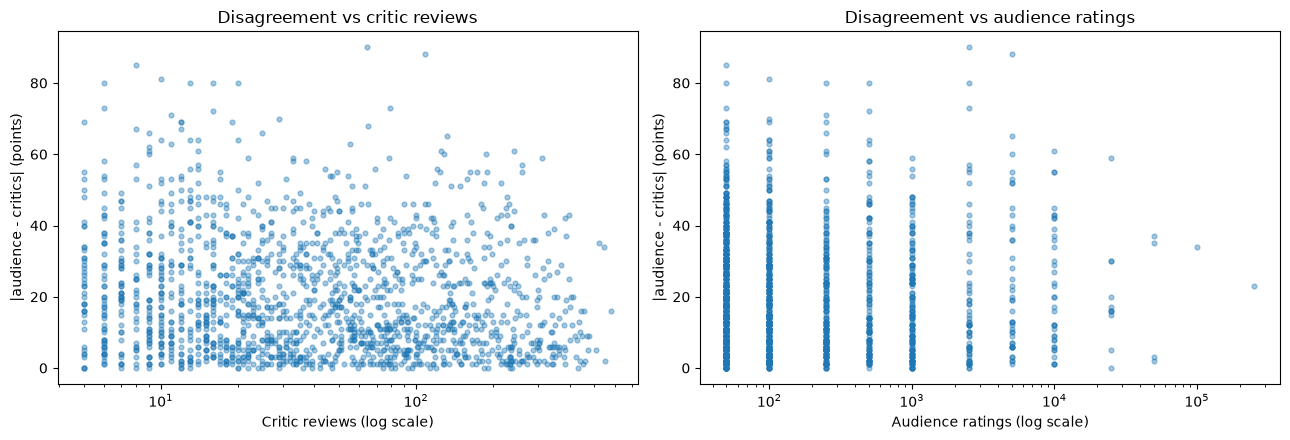

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, col, title in zip(axes, ["critic_reviews_count", "audience_rating_count"],
                          ["Critic reviews", "Audience ratings"]):
    data = rt[(rt[col] > 0)]
    ax.scatter(data[col], data["abs_gap"], alpha=0.4, s=12)
    ax.set_xscale("log")
    ax.set(xlabel=f"{title} (log scale)", ylabel="|audience - critics| (points)", title=f"Disagreement vs {title.lower()}")

plt.tight_layout()
save_fig("Disagreement vs number of reviews")
plt.show()

Le nuage montre beaucoup de dispersion à tous les niveaux, avec un lien faible entre le nombre d'avis (échelle log) et le désaccord.

In [26]:
# Is a score based on few reviews more extreme?
# extreme = very close to 0 or 100 (<= 10 or >= 90) / distance from 50 (the middle of the scale)
def extremeness_by_group(frame, count_col, score_col):
    data = frame.dropna(subset=[count_col, score_col]).copy()
    data["group"] = quartile_group(data[count_col])
    data["dist_from_50"] = (data[score_col] - 50).abs()
    data["is_extreme"] = (data[score_col] <= 10) | (data[score_col] >= 90)
    return data.groupby("group", observed=True).agg(
        min_count=(count_col, "min"),
        max_count=(count_col, "max"),
        n_films=(score_col, "count"),
        median_dist_from_50=("dist_from_50", "median"),
        std_score=(score_col, "std"),
        pct_extreme=("is_extreme", lambda s: s.mean() * 100),
    )

critic_ext = extremeness_by_group(rt, "critic_reviews_count", "critic_score_percentage")
audience_ext = extremeness_by_group(rt, "audience_rating_count", "audience_score_percentage")

print("CRITIC scores by number of critic reviews:")
display(critic_ext.round(1))
print("AUDIENCE scores by number of audience ratings:")
display(audience_ext.round(1))

CRITIC scores by number of critic reviews:


,min_count,max_count,n_films,median_dist_from_50,std_score,pct_extreme
group,,,,,,
1 (fewest),5.0,15.0,418,30.0,31.1,28.2
2,15.0,37.0,418,26.0,26.0,20.8
3,37.0,99.0,418,32.5,24.2,31.1
4 (most),99.0,581.0,418,31.0,21.5,30.1


AUDIENCE scores by number of audience ratings:


,min_count,max_count,n_films,median_dist_from_50,std_score,pct_extreme
group,,,,,,
1 (fewest),50.0,50.0,418,21.0,22.9,13.9
2,50.0,100.0,418,21.0,21.4,11.2
3,100.0,500.0,418,23.0,21.3,17.9
4 (most),500.0,250000.0,418,31.0,18.7,26.6


Pour les critiques, l'écart-type baisse avec le nombre d'avis (31 à 22) mais la part de scores extrêmes n'a pas de tendance claire. Pour le public, les scores extrêmes sont plus fréquents avec plus de notes (14 % à 27 %) : l'hypothèse « peu d'avis, score plus extrême » n'est pas confirmée.

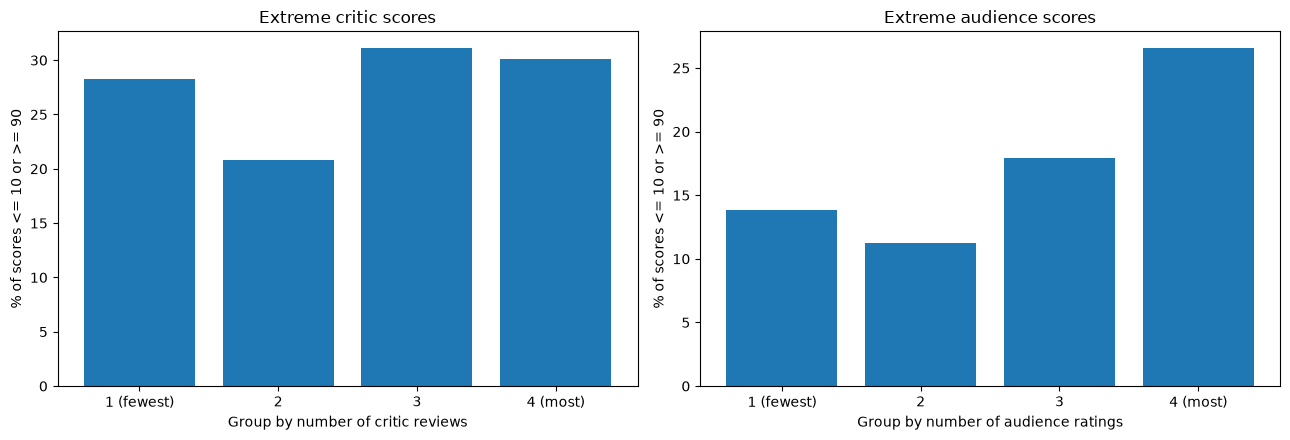

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(critic_ext.index.astype(str), critic_ext["pct_extreme"])
axes[0].set(xlabel="Group by number of critic reviews", ylabel="% of scores <= 10 or >= 90",
            title="Extreme critic scores")

axes[1].bar(audience_ext.index.astype(str), audience_ext["pct_extreme"])
axes[1].set(xlabel="Group by number of audience ratings", ylabel="% of scores <= 10 or >= 90",
            title="Extreme audience scores")

plt.tight_layout()
save_fig("Extreme scores by number of reviews")
plt.show()

Les barres reprennent ces pourcentages : pas de lien net pour les critiques, hausse pour le public.

Note: a critic score is a percentage computed on the number of reviews. With very few reviews it can only take a few values (for example only multiples of 20 with 5 reviews), so extreme scores are mechanically more frequent. This is a statistical effect, not necessarily a difference of opinion.

###
5. **Les scores vérifiés** (`rotten_is_audience_rating_verified`) **diffèrent-ils des non vérifiés ?**  
   *Attention : avant d'interpréter, vérifier ce que cette colonne signifie réellement.*

In [28]:
print(rt["is_audience_rating_verified"].value_counts(dropna=False))

mapping = {True: "verified", False: "not verified", "True": "verified", "False": "not verified"}
rt["verified"] = rt["is_audience_rating_verified"].map(mapping)
rt_tmdb["verified"] = rt_tmdb["is_audience_rating_verified"].map(mapping)

print("Films with a known value:", rt["verified"].notna().sum(), "/", len(rt))

is_audience_rating_verified
False    1171
True      501
Name: count, dtype: int64
Films with a known value: 1672 / 1672


501 films ont un score vérifié et 1 171 non vérifié ; aucune valeur inconnue, donc les deux groupes sont comparables en taille.

In [29]:
rows = []
for name, g in rt.dropna(subset=["verified"]).groupby("verified"):
    rows.append({
        "verified": name,
        "n_films": len(g),
        "median_critic": g["critic_score_percentage"].median(),
        "median_audience": g["audience_score_percentage"].median(),
        "median_gap": g["gap"].median(),
        "median_abs_gap": g["abs_gap"].median(),
        "median_audience_ratings": g["audience_rating_count"].median(),
        "spearman_critic_vs_audience": g["critic_score_percentage"].corr(g["audience_score_percentage"], method="spearman"),
    })
display(pd.DataFrame(rows).set_index("verified").round(2))

,n_films,median_critic,median_audience,median_gap,median_abs_gap,median_audience_ratings,spearman_critic_vs_audience
verified,,,,,,,
not verified,1171,75.0,64.0,-7.0,17.0,100.0,0.49
verified,501,75.0,84.0,7.0,12.0,500.0,0.45


À score critique identique (75 % de médiane), le public vérifié note nettement plus haut (84 % contre 64 %). L'écart passe de −7 à +7 points, et les films vérifiés ont plus de notes (500 contre 100).

In [30]:
# consistency with TMDB, inside each group
rows = []
for name, g in rt_tmdb.dropna(subset=["verified"]).groupby("verified"):
    rows.append({
        "verified": name,
        "n_films": len(g),
        "median_tmdb_diff": g["tmdb_diff"].median(),
        "median_abs_tmdb_diff": g["tmdb_diff"].abs().median(),
        "spearman_audience_vs_tmdb": g["audience_score_percentage"].corr(g["tmdb_score_100"], method="spearman"),
    })
display(pd.DataFrame(rows).set_index("verified").round(2))

,n_films,median_tmdb_diff,median_abs_tmdb_diff,spearman_audience_vs_tmdb
verified,,,,
not verified,1156,1.64,13.28,0.53
verified,501,15.00,15.69,0.69


Le score vérifié est bien plus haut que TMDB × 10 (+15 contre +1,6 en médiane), mais il classe les films de façon plus cohérente avec TMDB (Spearman 0,69 contre 0,53).

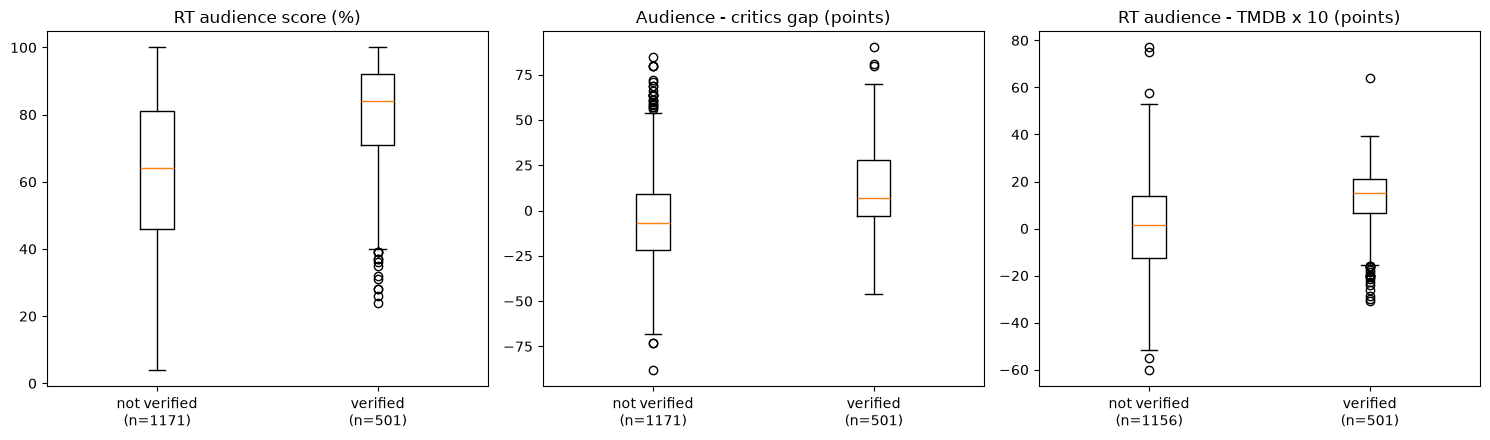

In [31]:
names = sorted(rt["verified"].dropna().unique())
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

panels = [
    (rt, "audience_score_percentage", "RT audience score (%)"),
    (rt, "gap", "Audience - critics gap (points)"),
    (rt_tmdb, "tmdb_diff", "RT audience - TMDB x 10 (points)"),
]
for ax, (frame, col, title) in zip(axes, panels):
    groups = [frame.loc[frame["verified"] == n, col].dropna() for n in names]
    ax.boxplot(groups)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels([f"{n}\n(n={len(g)})" for n, g in zip(names, groups)])
    ax.set_title(title)

plt.tight_layout()
save_fig("Scores by verified audience rating")
plt.show()

Les boîtes à moustaches montrent le même décalage vers le haut pour le public vérifié, un écart avec les critiques positif et un écart avec TMDB plus élevé.

## Summary of findings

1. **Accord critiques / public (n = 1 672).** Corrélation modérée (Spearman 0,44 ; Pearson 0,45). Écart médian de −2 points (moyen +0,2), mais 40 % des films ont plus de 20 points d'écart. Le public est plus généreux en Action (+10) et Aventure (+7), plus sévère en Horreur (−11,5) et en Documentaire (−7). L'accord varie selon le genre (Spearman de 0,18 à 0,58).

2. **Genres et films en désaccord.** 84 films (5,0 %) sont aimés du public mais rejetés par la critique (surtout Action et thrillers grand public) et 45 (2,7 %) l'inverse (surtout Horreur d'auteur et documentaires). Quelques cas extrêmes concernent des films à sujet politique ou controversé. Aucun schéma clair par année.

3. **Rotten (public) et TMDB × 10 (n = 1 657).** Classement assez cohérent (Spearman 0,62), mais les valeurs diffèrent : droite ajustée audience = 1,25 × (TMDB × 10) − 11,7, écart médian +7, seulement 36 % des films à ±10 points. Les écarts diminuent avec le nombre de votes TMDB (de 19,6 à 13,3 points en écart absolu médian) sans disparaître, et dépendent du genre (de −3,8 à +16,6) plus que de l'année. Les plus grands écarts viennent souvent de films avec très peu de votes.

4. **Nombre d'avis.** Plus il y a d'avis critiques, plus l'écart absolu baisse (de 19 à 12 points), mais la corrélation ne monte pas. Les scores avec peu d'avis ne sont pas systématiquement plus extrêmes ; pour le public, les scores extrêmes sont plutôt plus fréquents avec beaucoup de notes (14 % contre 27 %). `audience_rating_count` est arrondi, donc à utiliser avec prudence.

5. **Scores vérifiés (501) et non vérifiés (1 171).** Le score public vérifié est plus haut (médiane 84 % contre 64 %) alors que les critiques sont identiques (75 %). L'écart avec la critique passe de −7 à +7 points. Les vérifiés ont aussi plus de notes (500 contre 100 en médiane). La signification exacte de la colonne reste à confirmer.

## Limitations

1. Only the films present in both TMDB and Rotten Tomatoes are used. The match is made on the normalized title and the release year, so it can miss films (different titles) and the sample is probably biased towards well-known films.
2. TMDB only contains the 10 000 most popular films of each year (API limit), so the TMDB side already favours popular films.
3. The scales are not the same: TMDB is an average on 0-10 from TMDB users, the Rotten Tomatoes scores are percentages. We compare trends (Spearman) and differences in points, not exact equivalences.
4. A score computed on very few reviews is noisy, and a critic score on a few reviews can only take a few values.
5. Missing values change the number of films from one analysis to another: the `n_films` column tells how many films each result is based on.
6. `audience_rating_count` looks rounded on at least one film (25 000), so it is approximate. To check.
7. The meaning of `is_audience_rating_verified` has to be checked on Rotten Tomatoes before interpreting the verified vs not verified comparison.
8. Correlation is not causation.